# 1. Datos y protocolo experimental

## 1.1 Carga de Iris

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score

In [2]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()

## 1.2 Descripción del dataset

Cada instancia (fila) de Iris representa una flor, las cuatro características son la longitud y el ancho del sépalo y del pétalo de la flor, todos estos medidos en centimetros (cm). El target indica si es: setosa, versicolor o virginica. El dataset en total contiene 150 instancias, 50 por clase.

In [3]:
# Que representa cada instancia
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [4]:
# Numero de instancias (filas) y caracteristicas (columnas)
iris_x = iris.data.shape[0]
iris_y = iris.data.shape[1]

print("Numero de instancias: ", iris_x)
print("Numero de caracteristicas: ", iris_y)

Numero de instancias:  150
Numero de caracteristicas:  4


In [5]:
# Nombre y significado de cada caracteristica
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [6]:
# Clases y cantidad de ejemplos por clase
print(iris.target_names) # Clases

# Ejemplos por clase
import pandas as pd 
iris_df = load_iris(as_frame=True).frame
ejemplos = iris_df['target'].value_counts()
print(ejemplos)

['setosa' 'versicolor' 'virginica']
target
0    50
1    50
2    50
Name: count, dtype: int64


In [7]:
# Dimension de la matriz de caracteristicas y del vector de etiquetas
print(iris.data.shape)
print(iris.target.shape)

(150, 4)
(150,)


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


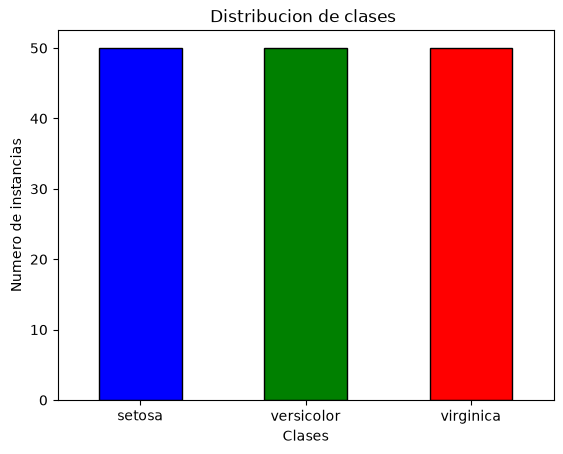

In [8]:
# Tabla con 5 ejemplos y graficos de distribucion de clases
import matplotlib.pyplot as plt
iris_df['target'] = pd.Categorical.from_codes(iris.target, iris.target_names)
ejemplos = iris_df['target'].value_counts() 
print(iris_df.head(5))

ejemplos.plot(kind='bar',color=['blue', 'green', 'red'], edgecolor='black')
plt.title('Distribucion de clases ')
plt.xlabel('Clases')
plt.ylabel('Numero de instancias')
plt.xticks(rotation=0)
plt.show()

## 1.3 Creación de particiones

In [9]:
# Division train-test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=1
)
# Division train-validacion
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    stratify=y_trainval,
    random_state=1
)

# 2. Comparación de clasificadores

## Predicciones Iniciales

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

Los más sensibles a la escala son la regresión logística, el SVM lineal y el MLP, porque el tamaño de cada característica influye en sus coeficientes, márgenes y gradientes. Los modelos basados en árboles (árbol de decisión, Random Forest y Gradient Boosting) casi no cambian al reescalar, porque dividen mediante umbrales. Gaussian Naive Bayes tampoco depende de distancias y suele ser mucho menos sensible a la escala. Aun así, en este trabajo se estandarizan todos los clasificadores para cumplir el mismo protocolo. Regularizar y estandarizar no son lo mismo.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Espero que la regresión logística y el SVM lineal produzcan las fronteras más simples, porque separan las clases mediante hiperplanos lineales. Un árbol produce regiones complejas (como escaleras) y un MLP puede aprender fronteras no lineales más flexibles (curvas o similares). 

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Sin analizar la distribución de los datos, sus relaciones, etc, no se puede asegurar que ningún modelo sea mejor que otro, ya que podrían separarse los datos tanto por una línea recta como por una curva más compleja, sin analizar lo mencionado no se puede afirmar nada.


## 2.1 Estandarización y criterio de selección

In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

## 2.2 Configuraciones iniciales y ajuste limitado

### Gaussian Naive Bayes

In [11]:
nb_inicial = GaussianNB(var_smoothing=1e-9)
nb_inicial.fit(X_train_scaled, y_train)
pred_nb_inicial = nb_inicial.predict(X_val_scaled)
accuracy_nb_inicial = accuracy_score(y_val, pred_nb_inicial)
f1_nb_inicial = f1_score(y_val, pred_nb_inicial, average="macro")

nb_alternativo = GaussianNB(var_smoothing=1e-7)
nb_alternativo.fit(X_train_scaled, y_train)
pred_nb_alternativo = nb_alternativo.predict(X_val_scaled)
accuracy_nb_alternativo = accuracy_score(y_val, pred_nb_alternativo)
f1_nb_alternativo = f1_score(y_val, pred_nb_alternativo, average="macro")

print("Accuracy inicial:", accuracy_nb_inicial, "F1 macro:", f1_nb_inicial)
print("Accuracy alternativa:", accuracy_nb_alternativo, "F1 macro:", f1_nb_alternativo)


Accuracy inicial: 0.9333333333333333 F1 macro: 0.9333333333333332
Accuracy alternativa: 0.9333333333333333 F1 macro: 0.9333333333333332


### Regresión logística multiclase

In [12]:
logistica_inicial = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=1
)
logistica_inicial.fit(X_train_scaled, y_train)
pred_logistica_inicial = logistica_inicial.predict(X_val_scaled)
accuracy_logistica_inicial = accuracy_score(y_val, pred_logistica_inicial)
f1_logistica_inicial = f1_score(y_val, pred_logistica_inicial, average="macro")

logistica_alternativa = LogisticRegression(
    C=0.1,
    solver="lbfgs",
    max_iter=2000,
    random_state=1
)
logistica_alternativa.fit(X_train_scaled, y_train)
pred_logistica_alternativa = logistica_alternativa.predict(X_val_scaled)
accuracy_logistica_alternativa = accuracy_score(y_val, pred_logistica_alternativa)
f1_logistica_alternativa = f1_score(y_val, pred_logistica_alternativa, average="macro")

print("Accuracy inicial:", accuracy_logistica_inicial, "F1 macro:", f1_logistica_inicial)
print("Accuracy alternativa:", accuracy_logistica_alternativa, "F1 macro:", f1_logistica_alternativa)

Accuracy inicial: 0.9333333333333333 F1 macro: 0.9333333333333332
Accuracy alternativa: 0.9333333333333333 F1 macro: 0.9333333333333332


### SVM lineal

In [13]:
svm_inicial = SVC(kernel="linear", C=1.0)
svm_inicial.fit(X_train_scaled, y_train)
pred_svm_inicial = svm_inicial.predict(X_val_scaled)
accuracy_svm_inicial = accuracy_score(y_val, pred_svm_inicial)
f1_svm_inicial = f1_score(y_val, pred_svm_inicial, average="macro")

svm_alternativo = SVC(kernel="linear", C=0.1)
svm_alternativo.fit(X_train_scaled, y_train)
pred_svm_alternativo = svm_alternativo.predict(X_val_scaled)
accuracy_svm_alternativo = accuracy_score(y_val, pred_svm_alternativo)
f1_svm_alternativo = f1_score(y_val, pred_svm_alternativo, average="macro")

print("Accuracy inicial:", accuracy_svm_inicial, "F1 macro:", f1_svm_inicial)
print("Accuracy alternativa:", accuracy_svm_alternativo, "F1 macro:", f1_svm_alternativo)

Accuracy inicial: 0.9333333333333333 F1 macro: 0.9326599326599326
Accuracy alternativa: 0.9333333333333333 F1 macro: 0.9326599326599326


### Árbol de decisión

In [14]:
arbol_inicial = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=1
)
arbol_inicial.fit(X_train_scaled, y_train)
pred_arbol_inicial = arbol_inicial.predict(X_val_scaled)
accuracy_arbol_inicial = accuracy_score(y_val, pred_arbol_inicial)
f1_arbol_inicial = f1_score(y_val, pred_arbol_inicial, average="macro")

arbol_alternativo = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=1
)
arbol_alternativo.fit(X_train_scaled, y_train)
pred_arbol_alternativo = arbol_alternativo.predict(X_val_scaled)
accuracy_arbol_alternativo = accuracy_score(y_val, pred_arbol_alternativo)
f1_arbol_alternativo = f1_score(y_val, pred_arbol_alternativo, average="macro")

print("Accuracy inicial:", accuracy_arbol_inicial, "F1 macro:", f1_arbol_inicial)
print("Accuracy alternativa:", accuracy_arbol_alternativo, "F1 macro:", f1_arbol_alternativo)

Accuracy inicial: 0.9 F1 macro: 0.899749373433584
Accuracy alternativa: 0.9 F1 macro: 0.899749373433584


### Random Forest

In [15]:
forest_inicial = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_inicial.fit(X_train_scaled, y_train)
pred_forest_inicial = forest_inicial.predict(X_val_scaled)
accuracy_forest_inicial = accuracy_score(y_val, pred_forest_inicial)
f1_forest_inicial = f1_score(y_val, pred_forest_inicial, average="macro")

forest_alternativo = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_alternativo.fit(X_train_scaled, y_train)
pred_forest_alternativo = forest_alternativo.predict(X_val_scaled)
accuracy_forest_alternativo = accuracy_score(y_val, pred_forest_alternativo)
f1_forest_alternativo = f1_score(y_val, pred_forest_alternativo, average="macro")

print("Accuracy inicial:", accuracy_forest_inicial, "F1 macro:", f1_forest_inicial)
print("Accuracy alternativa:", accuracy_forest_alternativo, "F1 macro:", f1_forest_alternativo)

Accuracy inicial: 0.9333333333333333 F1 macro: 0.9326599326599326
Accuracy alternativa: 0.9333333333333333 F1 macro: 0.9326599326599326


### Gradient Boosting

In [16]:
gradient_inicial = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_inicial.fit(X_train_scaled, y_train)
pred_gradient_inicial = gradient_inicial.predict(X_val_scaled)
accuracy_gradient_inicial = accuracy_score(y_val, pred_gradient_inicial)
f1_gradient_inicial = f1_score(y_val, pred_gradient_inicial, average="macro")

gradient_alternativo = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_alternativo.fit(X_train_scaled, y_train)
pred_gradient_alternativo = gradient_alternativo.predict(X_val_scaled)
accuracy_gradient_alternativo = accuracy_score(y_val, pred_gradient_alternativo)
f1_gradient_alternativo = f1_score(y_val, pred_gradient_alternativo, average="macro")

print("Accuracy inicial:", accuracy_gradient_inicial, "F1 macro:", f1_gradient_inicial)
print("Accuracy alternativa:", accuracy_gradient_alternativo, "F1 macro:", f1_gradient_alternativo)

Accuracy inicial: 0.9333333333333333 F1 macro: 0.9326599326599326
Accuracy alternativa: 0.9333333333333333 F1 macro: 0.9326599326599326


### MLP de clasificación

In [17]:
mlp_inicial = MLPClassifier(
    hidden_layer_sizes=(20,),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=3000,
    early_stopping=False,
    random_state=1
)
mlp_inicial.fit(X_train_scaled, y_train)
pred_mlp_inicial = mlp_inicial.predict(X_val_scaled)
accuracy_mlp_inicial = accuracy_score(y_val, pred_mlp_inicial)
f1_mlp_inicial = f1_score(y_val, pred_mlp_inicial, average="macro")

mlp_alternativo = MLPClassifier(
    hidden_layer_sizes=(20,),
    activation="relu",
    solver="adam",
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=3000,
    early_stopping=False,
    random_state=1
)
mlp_alternativo.fit(X_train_scaled, y_train)
pred_mlp_alternativo = mlp_alternativo.predict(X_val_scaled)
accuracy_mlp_alternativo = accuracy_score(y_val, pred_mlp_alternativo)
f1_mlp_alternativo = f1_score(y_val, pred_mlp_alternativo, average="macro")

print("Accuracy inicial:", accuracy_mlp_inicial, "F1 macro:", f1_mlp_inicial)
print("Accuracy alternativa:", accuracy_mlp_alternativo, "F1 macro:", f1_mlp_alternativo)

Accuracy inicial: 0.9 F1 macro: 0.899749373433584
Accuracy alternativa: 0.9 F1 macro: 0.899749373433584


## 2.3 Comparación en validación

La tabla contiene exactamente dos configuraciones por algoritmo: la inicial y una alternativa. La partición de prueba todavía no se utiliza.

In [18]:
tabla_validacion = pd.DataFrame([
    {"Modelo": "Gaussian Naive Bayes", "Configuracion": "Inicial", "Cambio principal": "var_smoothing=1e-9", "Accuracy validacion": accuracy_nb_inicial, "F1 macro validacion": f1_nb_inicial},
    {"Modelo": "Gaussian Naive Bayes", "Configuracion": "Alternativa", "Cambio principal": "var_smoothing=1e-7", "Accuracy validacion": accuracy_nb_alternativo, "F1 macro validacion": f1_nb_alternativo},
    {"Modelo": "Regresion logistica", "Configuracion": "Inicial", "Cambio principal": "C=1.0", "Accuracy validacion": accuracy_logistica_inicial, "F1 macro validacion": f1_logistica_inicial},
    {"Modelo": "Regresion logistica", "Configuracion": "Alternativa", "Cambio principal": "C=0.1", "Accuracy validacion": accuracy_logistica_alternativa, "F1 macro validacion": f1_logistica_alternativa},
    {"Modelo": "SVM lineal", "Configuracion": "Inicial", "Cambio principal": "C=1.0", "Accuracy validacion": accuracy_svm_inicial, "F1 macro validacion": f1_svm_inicial},
    {"Modelo": "SVM lineal", "Configuracion": "Alternativa", "Cambio principal": "C=0.1", "Accuracy validacion": accuracy_svm_alternativo, "F1 macro validacion": f1_svm_alternativo},
    {"Modelo": "Arbol de decision", "Configuracion": "Inicial", "Cambio principal": "max_depth=3", "Accuracy validacion": accuracy_arbol_inicial, "F1 macro validacion": f1_arbol_inicial},
    {"Modelo": "Arbol de decision", "Configuracion": "Alternativa", "Cambio principal": "max_depth=2", "Accuracy validacion": accuracy_arbol_alternativo, "F1 macro validacion": f1_arbol_alternativo},
    {"Modelo": "Random Forest", "Configuracion": "Inicial", "Cambio principal": "min_samples_leaf=1", "Accuracy validacion": accuracy_forest_inicial, "F1 macro validacion": f1_forest_inicial},
    {"Modelo": "Random Forest", "Configuracion": "Alternativa", "Cambio principal": "min_samples_leaf=2", "Accuracy validacion": accuracy_forest_alternativo, "F1 macro validacion": f1_forest_alternativo},
    {"Modelo": "Gradient Boosting", "Configuracion": "Inicial", "Cambio principal": "learning_rate=0.1", "Accuracy validacion": accuracy_gradient_inicial, "F1 macro validacion": f1_gradient_inicial},
    {"Modelo": "Gradient Boosting", "Configuracion": "Alternativa", "Cambio principal": "learning_rate=0.05", "Accuracy validacion": accuracy_gradient_alternativo, "F1 macro validacion": f1_gradient_alternativo},
    {"Modelo": "MLP", "Configuracion": "Inicial", "Cambio principal": "alpha=0.0001", "Accuracy validacion": accuracy_mlp_inicial, "F1 macro validacion": f1_mlp_inicial},
    {"Modelo": "MLP", "Configuracion": "Alternativa", "Cambio principal": "alpha=0.01", "Accuracy validacion": accuracy_mlp_alternativo, "F1 macro validacion": f1_mlp_alternativo}
])

tabla_validacion.sort_values(
    by=["F1 macro validacion", "Accuracy validacion"],
    ascending=False
).reset_index(drop=True)

,Modelo,Configuracion,Cambio principal,Accuracy validacion,F1 macro validacion
0,Gaussian Naive Bayes,Inicial,var_smoothing=1e-9,0.933333,0.933333
1,Gaussian Naive Bayes,Alternativa,var_smoothing=1e-7,0.933333,0.933333
2,Regresion logistica,Inicial,C=1.0,0.933333,0.933333
3,Regresion logistica,Alternativa,C=0.1,0.933333,0.933333
4,SVM lineal,Inicial,C=1.0,0.933333,0.932660
5,SVM lineal,Alternativa,C=0.1,0.933333,0.932660
6,Random Forest,Inicial,min_samples_leaf=1,0.933333,0.932660
7,Random Forest,Alternativa,min_samples_leaf=2,0.933333,0.932660
8,Gradient Boosting,Inicial,learning_rate=0.1,0.933333,0.932660
9,Gradient Boosting,Alternativa,learning_rate=0.05,0.933333,0.932660


## 2.4 Configuraciones congeladas

In [19]:
tabla_configuraciones_congeladas = pd.DataFrame([
    {"Modelo": "Gaussian Naive Bayes", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "var_smoothing=1e-9", "Accuracy validacion": accuracy_nb_inicial, "F1 macro validacion": f1_nb_inicial},
    {"Modelo": "Regresion logistica", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "C=1.0", "Accuracy validacion": accuracy_logistica_inicial, "F1 macro validacion": f1_logistica_inicial},
    {"Modelo": "SVM lineal", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "C=1.0", "Accuracy validacion": accuracy_svm_inicial, "F1 macro validacion": f1_svm_inicial},
    {"Modelo": "Arbol de decision", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "max_depth=3", "Accuracy validacion": accuracy_arbol_inicial, "F1 macro validacion": f1_arbol_inicial},
    {"Modelo": "Random Forest", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "min_samples_leaf=1", "Accuracy validacion": accuracy_forest_inicial, "F1 macro validacion": f1_forest_inicial},
    {"Modelo": "Gradient Boosting", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "learning_rate=0.1", "Accuracy validacion": accuracy_gradient_inicial, "F1 macro validacion": f1_gradient_inicial},
    {"Modelo": "MLP", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "alpha=0.0001", "Accuracy validacion": accuracy_mlp_inicial, "F1 macro validacion": f1_mlp_inicial}
])

tabla_configuraciones_congeladas

,Modelo,Configuracion elegida,Hiperparametro congelado,Accuracy validacion,F1 macro validacion
0,Gaussian Naive Bayes,Inicial,var_smoothing=1e-9,0.933333,0.933333
1,Regresion logistica,Inicial,C=1.0,0.933333,0.933333
2,SVM lineal,Inicial,C=1.0,0.933333,0.932660
3,Arbol de decision,Inicial,max_depth=3,0.900000,0.899749
4,Random Forest,Inicial,min_samples_leaf=1,0.933333,0.932660
5,Gradient Boosting,Inicial,learning_rate=0.1,0.933333,0.932660
6,MLP,Inicial,alpha=0.0001,0.900000,0.899749


## 2.5 Preparación del entrenamiento final

In [20]:
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

scaler_final = StandardScaler()
X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_test_scaled = scaler_final.transform(X_test)

print("Entrenamiento final:", X_train_final.shape)
print("Prueba:", X_test.shape)

Entrenamiento final: (120, 4)
Prueba: (30, 4)


## 2.6 Modelos finales y evaluación única en test

### Gaussian Naive Bayes final

In [21]:
nb_final = GaussianNB(
    var_smoothing=1e-9
)
nb_final.fit(X_train_final_scaled, y_train_final)
pred_nb_test = nb_final.predict(X_test_scaled)
accuracy_nb_test = accuracy_score(y_test, pred_nb_test)
f1_nb_test = f1_score(y_test, pred_nb_test, average="macro")

### Regresión logística final

In [22]:
logistica_final = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=1
)
logistica_final.fit(X_train_final_scaled, y_train_final)
pred_logistica_test = logistica_final.predict(X_test_scaled)
accuracy_logistica_test = accuracy_score(y_test, pred_logistica_test)
f1_logistica_test = f1_score(y_test, pred_logistica_test, average="macro")

### SVM lineal final

In [23]:
svm_final = SVC(
    kernel="linear",
    C=1.0
)
svm_final.fit(X_train_final_scaled, y_train_final)
pred_svm_test = svm_final.predict(X_test_scaled)
accuracy_svm_test = accuracy_score(y_test, pred_svm_test)
f1_svm_test = f1_score(y_test, pred_svm_test, average="macro")

### Árbol de decisión final

In [24]:
arbol_final = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=1
)
arbol_final.fit(X_train_final_scaled, y_train_final)
pred_arbol_test = arbol_final.predict(X_test_scaled)
accuracy_arbol_test = accuracy_score(y_test, pred_arbol_test)
f1_arbol_test = f1_score(y_test, pred_arbol_test, average="macro")

### Random Forest final

In [25]:
forest_final = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_final.fit(X_train_final_scaled, y_train_final)
pred_forest_test = forest_final.predict(X_test_scaled)
accuracy_forest_test = accuracy_score(y_test, pred_forest_test)
f1_forest_test = f1_score(y_test, pred_forest_test, average="macro")

### Gradient Boosting final

In [26]:
gradient_final = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_final.fit(X_train_final_scaled, y_train_final)
pred_gradient_test = gradient_final.predict(X_test_scaled)
accuracy_gradient_test = accuracy_score(y_test, pred_gradient_test)
f1_gradient_test = f1_score(y_test, pred_gradient_test, average="macro")

### MLP final

In [27]:
mlp_final = MLPClassifier(
    hidden_layer_sizes=(20,),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=3000,
    early_stopping=False,
    random_state=1
)
mlp_final.fit(X_train_final_scaled, y_train_final)
pred_mlp_test = mlp_final.predict(X_test_scaled)
accuracy_mlp_test = accuracy_score(y_test, pred_mlp_test)
f1_mlp_test = f1_score(y_test, pred_mlp_test, average="macro")

## 2.7 Resultados finales de prueba

In [28]:
tabla_prueba = pd.DataFrame([
    {"Modelo": "Gaussian Naive Bayes", "Transformacion": "StandardScaler", "Hiperparametros principales": "var_smoothing=1e-9", "Accuracy de prueba": accuracy_nb_test, "F1 macro de prueba": f1_nb_test},
    {"Modelo": "Regresion logistica", "Transformacion": "StandardScaler", "Hiperparametros principales": "C=1.0, regularizacion L2 por defecto", "Accuracy de prueba": accuracy_logistica_test, "F1 macro de prueba": f1_logistica_test},
    {"Modelo": "SVM lineal", "Transformacion": "StandardScaler", "Hiperparametros principales": "kernel=linear, C=1.0", "Accuracy de prueba": accuracy_svm_test, "F1 macro de prueba": f1_svm_test},
    {"Modelo": "Arbol de decision", "Transformacion": "StandardScaler", "Hiperparametros principales": "max_depth=3, min_samples_leaf=2", "Accuracy de prueba": accuracy_arbol_test, "F1 macro de prueba": f1_arbol_test},
    {"Modelo": "Random Forest", "Transformacion": "StandardScaler", "Hiperparametros principales": "n_estimators=300, min_samples_leaf=1", "Accuracy de prueba": accuracy_forest_test, "F1 macro de prueba": f1_forest_test},
    {"Modelo": "Gradient Boosting", "Transformacion": "StandardScaler", "Hiperparametros principales": "n_estimators=100, learning_rate=0.1, max_depth=2", "Accuracy de prueba": accuracy_gradient_test, "F1 macro de prueba": f1_gradient_test},
    {"Modelo": "MLP", "Transformacion": "StandardScaler", "Hiperparametros principales": "hidden_layer_sizes=(20,), alpha=0.0001", "Accuracy de prueba": accuracy_mlp_test, "F1 macro de prueba": f1_mlp_test}
])

tabla_prueba = tabla_prueba.sort_values(
    by=["F1 macro de prueba", "Accuracy de prueba"],
    ascending=False
).reset_index(drop=True)

tabla_prueba

,Modelo,Transformacion,Hiperparametros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,var_smoothing=1e-9,0.966667,0.966583
1,Regresion logistica,StandardScaler,"C=1.0, regularizacion L2 por defecto",0.966667,0.966583
2,SVM lineal,StandardScaler,"kernel=linear, C=1.0",0.966667,0.966583
3,Arbol de decision,StandardScaler,"max_depth=3, min_samples_leaf=2",0.966667,0.966583
4,Random Forest,StandardScaler,"n_estimators=300, min_samples_leaf=1",0.966667,0.966583
5,Gradient Boosting,StandardScaler,"n_estimators=100, learning_rate=0.1, max_depth=2",0.966667,0.966583
6,MLP,StandardScaler,"hidden_layer_sizes=(20,), alpha=0.0001",0.966667,0.966583


## 2.8 Matrices de confusión

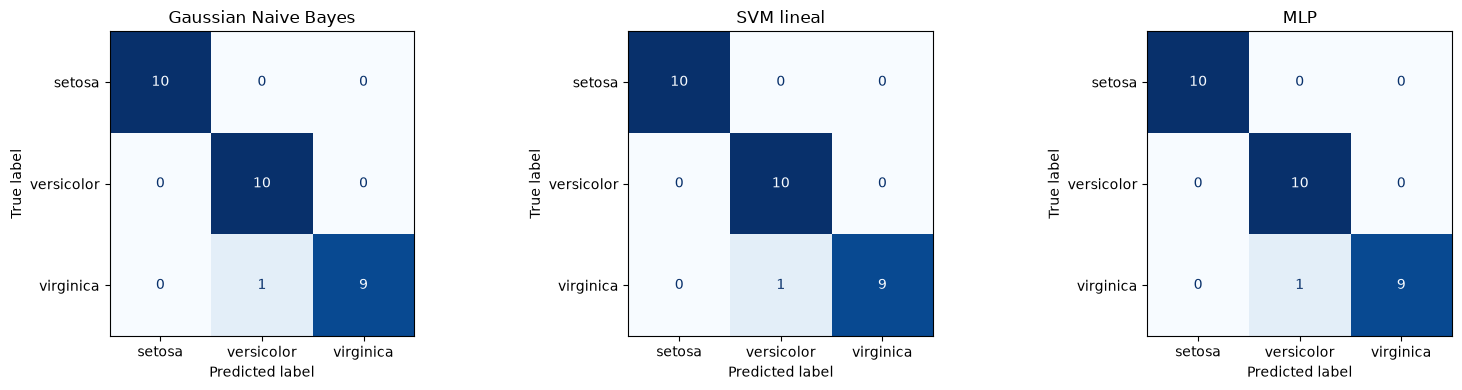

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_nb_test,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)
axes[0].set_title("Gaussian Naive Bayes")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_svm_test,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Blues",
    colorbar=False,
    ax=axes[1]
)
axes[1].set_title("SVM lineal")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_mlp_test,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Blues",
    colorbar=False,
    ax=axes[2]
)
axes[2].set_title("MLP")

plt.tight_layout()
plt.show()

## 2.9 Interpretación

1. **¿Cuál fue el modelo con mejor desempeño?** 

Los modelos empataron con accuracy de 0.9667 y F1 macro de 0.9666 en test, esto no demuestra que estos modelos tengan la misma capacidad de generalizacion. El test contiene solo 30 observaciones donde cada error representa aproximadamente 3.33 puntos.

2. **¿Cuál fue el modelo más sencillo de programar?** 

Gaussian Naive Bayes fue el modelo más sencillo de programar porque puede crearse y entrenarse directamente y tiene muy pocos hiperparámetros para configurar.

3. **¿Accuracy y F1 macro cuentan la misma historia?** 

En este dataset los modelos empataron en accuracy y f1 macro por lo que se llega a la misma conclusión, sin embargo no explican lo mismo ya que se calculan de forma distinta.

4. **¿Cuál es la diferencia entre macro y micro?** 

En F1 macro se calcula un F1 por clase y después se obtiene la media sin ponderar, de modo que todas las clases tienen el mismo peso. F1 micro suma primero los verdaderos positivos, falsos positivos y falsos negativos de todas las clases y luego calcula un único F1, por eso cada observación pesa por igual y las clases con mas cantidad pesan mas.

5. **¿Qué aporta el MLP frente a un modelo lineal?** 

MLP puede aprender fronteras no lineales mediante las capas ocultas y las distintas funciones de activacion que se tienen, a diferencia de la regresion logistica o SVM lineal que solo pueden crear fronteras lineales, eso no garantiza mejores resultados ya que es sensible a escala, convergencia, etc.

## 2.10 Dos errores de clasificación


In [30]:
predicciones_test = {
    "Naive Bayes": pred_nb_test,
    "Regresion logistica": pred_logistica_test,
    "SVM lineal": pred_svm_test,
    "Arbol de decision": pred_arbol_test,
    "Random Forest": pred_forest_test,
    "Gradient Boosting": pred_gradient_test,
    "MLP": pred_mlp_test
}

errores_test = []

for nombre_modelo, predicciones in predicciones_test.items():
    posiciones_error = np.flatnonzero(np.asarray(y_test) != predicciones)

    for posicion in posiciones_error:
        errores_test.append({
            "Modelo": nombre_modelo,
            "Indice original": X_test.index[posicion],
            "Clase real": iris.target_names[np.asarray(y_test)[posicion]],
            "Clase predicha": iris.target_names[predicciones[posicion]]
        })

pd.DataFrame(errores_test)

,Modelo,Indice original,Clase real,Clase predicha
0,Naive Bayes,106,virginica,versicolor
1,Regresion logistica,106,virginica,versicolor
2,SVM lineal,106,virginica,versicolor
3,Arbol de decision,106,virginica,versicolor
4,Random Forest,106,virginica,versicolor
5,Gradient Boosting,106,virginica,versicolor
6,MLP,106,virginica,versicolor


In [31]:
posiciones_error_val = np.flatnonzero(np.asarray(y_val) != pred_nb_inicial)

errores_validacion_nb = X_val.iloc[posiciones_error_val].copy()
errores_validacion_nb.insert(0, "Indice original", X_val.index[posiciones_error_val])
errores_validacion_nb["Clase real"] = iris.target_names[np.asarray(y_val)[posiciones_error_val]]
errores_validacion_nb["Clase predicha"] = iris.target_names[pred_nb_inicial[posiciones_error_val]]

errores_validacion_nb

,Indice original,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase real,Clase predicha
133,133,6.3,2.8,5.1,1.5,virginica,versicolor
70,70,5.9,3.2,4.8,1.8,versicolor,virginica


In [32]:
datos_entrenamiento = X_train.copy()
datos_entrenamiento["Clase"] = np.asarray(y_train)

medias_por_clase = datos_entrenamiento.groupby("Clase").mean()
medias_por_clase.index = [iris.target_names[clase] for clase in medias_por_clase.index]

medias_por_clase

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.983333,3.356667,1.470000,0.233333
versicolor,5.960000,2.806667,4.273333,1.310000
virginica,6.740000,2.990000,5.720000,2.063333


Todos los modelos cometieron un solo error en test: la fila cuyo índice original es 106, donde la clase real era virginica y se predijo versicolor. Como en test existe un solo caso mal clasificado y test no debe utilizarse para buscar más ejemplos, se analizan además los dos errores de validación de Naive Bayes, cuyos índices originales son 133 y 70.

Para la observación 133 se tiene que pertenecía a virginica y se clasificó como versicolor. Sus medidas son:

- Longitud del sépalo: 6.3.
- Ancho del sépalo: 2.8.
- Longitud del pétalo: 5.1.
- Ancho del pétalo: 1.5.

El ancho del sépalo casi coincide con la media de versicolor, que es aproximadamente 2.807, y el ancho del pétalo también está más cerca de la media de versicolor que de la de virginica. Esto es compatible con que la observación esté en una zona difícil de separar entre ambas clases, pero comparar medias no demuestra por sí solo que exista solapamiento ni identifica la causa del error.

La observación 70 pertenecía a versicolor y fue clasificada como virginica. Sus medidas son:

- Longitud del sépalo: 5.9.
- Ancho del sépalo: 3.2.
- Longitud del pétalo: 4.8.
- Ancho del pétalo: 1.8.

La longitud del sépalo y la del pétalo están más próximas a las medias de versicolor, mientras que los dos anchos están más próximos a las medias de virginica. Esto muestra proximidad a ambas medias, no que el modelo haya usado necesariamente esas características como causa directa de la predicción.

*Se puede concluir que las dos observaciones tienen características próximas a las medias de ambas clases. No se puede concluir que una característica específica causó el error, que haya errores de medición ni que el modelo esté defectuoso.*

# 3. Comparación de modelos de regresión

## 3.1 Dataset Diabetes

Cada instancia representa datos basales de un paciente. El target es una medida cuantitativa de progresión de la enfermedad un año después de la medición inicial. El dataset contiene 442 observaciones y 10 características: edad ("age"), sexo ("sex"), índice de masa corporal ("bmi"), presión arterial media ("bp") y seis variables séricas ("s1" a "s6").

Tambien se encontró que el dataset de diabetes usa por defecto el scaled=true lo que implica que las caracteristicas ya fueron centradas y escaladas

In [33]:
diabetes = load_diabetes(as_frame=True)
X_reg = diabetes.data.copy()
y_reg = diabetes.target.copy()

print("Dimensiones de X:", X_reg.shape)
print("Dimensiones de y:", y_reg.shape)
print("Caracteristicas:", list(X_reg.columns))
print(y_reg.describe())

X_reg.head()

Dimensiones de X: (442, 10)
Dimensiones de y: (442,)
Caracteristicas: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 3.2 Predicción inicial

**¿Espero que un modelo más flexible produzca siempre un menor error en datos nuevos?**

No ya que un modelo flexible si bien puede representar relaciones mas complejas y reducir el error en entrenamiento puede aprender ruido o cosas particulares de la muestra que se le de. Eso incremente el riesgo de overfitting y llegar a empeorar el error en test, un modelo menos flexible puede generalizar mejor si la relacion es simple o si los datos son limitados.

## 3.3 Particiones de entrenamiento, validación y prueba

In [34]:
X_reg_trainval, X_reg_test, y_reg_trainval, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=1
)

X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg_trainval,
    y_reg_trainval,
    test_size=0.25,
    random_state=1
)

print("Entrenamiento:", X_reg_train.shape, y_reg_train.shape)
print("Validacion:", X_reg_val.shape, y_reg_val.shape)
print("Prueba:", X_reg_test.shape, y_reg_test.shape)

Entrenamiento: (264, 10) (264,)
Validacion: (89, 10) (89,)
Prueba: (89, 10) (89,)


## 3.4 Configuraciones iniciales y criterio de selección

### Regresión lineal

In [35]:
lineal_inicial = LinearRegression()
lineal_inicial.fit(X_reg_train, y_reg_train)
pred_lineal_val = lineal_inicial.predict(X_reg_val)

mae_lineal_val = mean_absolute_error(y_reg_val, pred_lineal_val)
rmse_lineal_val = mean_squared_error(y_reg_val, pred_lineal_val) ** 0.5
r2_lineal_val = r2_score(y_reg_val, pred_lineal_val)

print("MAE inicial:", mae_lineal_val, "RMSE:", rmse_lineal_val, "R²:", r2_lineal_val)

MAE inicial: 47.68642374017336 RMSE: 58.26059969562506 R²: 0.49340244938785394


### Ridge

In [36]:
ridge_inicial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])
ridge_inicial.fit(X_reg_train, y_reg_train)
pred_ridge_inicial = ridge_inicial.predict(X_reg_val)
mae_ridge_inicial = mean_absolute_error(y_reg_val, pred_ridge_inicial)
rmse_ridge_inicial = mean_squared_error(y_reg_val, pred_ridge_inicial) ** 0.5
r2_ridge_inicial = r2_score(y_reg_val, pred_ridge_inicial)

ridge_alternativo = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=10.0))
])
ridge_alternativo.fit(X_reg_train, y_reg_train)
pred_ridge_alternativo = ridge_alternativo.predict(X_reg_val)
mae_ridge_alternativo = mean_absolute_error(y_reg_val, pred_ridge_alternativo)
rmse_ridge_alternativo = mean_squared_error(y_reg_val, pred_ridge_alternativo) ** 0.5
r2_ridge_alternativo = r2_score(y_reg_val, pred_ridge_alternativo)

print("MAE inicial:", mae_ridge_inicial, "RMSE:", rmse_ridge_inicial, "R²:", r2_ridge_inicial)
print("MAE alternativa:", mae_ridge_alternativo, "RMSE:", rmse_ridge_alternativo, "R²:", r2_ridge_alternativo)

MAE inicial: 47.555642961761485 RMSE: 58.092230808846 R²: 0.49632627844337573
MAE alternativa: 47.298052292724954 RMSE: 57.883134020019355 R²: 0.4999455927121387


### Lasso

In [37]:
lasso_inicial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=1.0, max_iter=20000))
])
lasso_inicial.fit(X_reg_train, y_reg_train)
pred_lasso_inicial = lasso_inicial.predict(X_reg_val)
mae_lasso_inicial = mean_absolute_error(y_reg_val, pred_lasso_inicial)
rmse_lasso_inicial = mean_squared_error(y_reg_val, pred_lasso_inicial) ** 0.5
r2_lasso_inicial = r2_score(y_reg_val, pred_lasso_inicial)

lasso_alternativo = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=0.1, max_iter=20000))
])
lasso_alternativo.fit(X_reg_train, y_reg_train)
pred_lasso_alternativo = lasso_alternativo.predict(X_reg_val)
mae_lasso_alternativo = mean_absolute_error(y_reg_val, pred_lasso_alternativo)
rmse_lasso_alternativo = mean_squared_error(y_reg_val, pred_lasso_alternativo) ** 0.5
r2_lasso_alternativo = r2_score(y_reg_val, pred_lasso_alternativo)

print("MAE inicial:", mae_lasso_inicial, "RMSE:", rmse_lasso_inicial, "R²:", r2_lasso_inicial)
print("MAE alternativa:", mae_lasso_alternativo, "RMSE:", rmse_lasso_alternativo, "R²:", r2_lasso_alternativo)

MAE inicial: 47.25358459170839 RMSE: 57.63011629885118 R²: 0.5043076958362058
MAE alternativa: 47.46550823204428 RMSE: 57.99771438077363 R²: 0.4979639058243812


### kNN de regresión

In [38]:
knn_inicial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(n_neighbors=5, weights="uniform", p=2))
])
knn_inicial.fit(X_reg_train, y_reg_train)
pred_knn_inicial = knn_inicial.predict(X_reg_val)
mae_knn_inicial = mean_absolute_error(y_reg_val, pred_knn_inicial)
rmse_knn_inicial = mean_squared_error(y_reg_val, pred_knn_inicial) ** 0.5
r2_knn_inicial = r2_score(y_reg_val, pred_knn_inicial)

knn_alternativo = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(n_neighbors=10, weights="uniform", p=2))
])
knn_alternativo.fit(X_reg_train, y_reg_train)
pred_knn_alternativo = knn_alternativo.predict(X_reg_val)
mae_knn_alternativo = mean_absolute_error(y_reg_val, pred_knn_alternativo)
rmse_knn_alternativo = mean_squared_error(y_reg_val, pred_knn_alternativo) ** 0.5
r2_knn_alternativo = r2_score(y_reg_val, pred_knn_alternativo)

print("MAE inicial:", mae_knn_inicial, "RMSE:", rmse_knn_inicial, "R²:", r2_knn_inicial)
print("MAE alternativa:", mae_knn_alternativo, "RMSE:", rmse_knn_alternativo, "R²:", r2_knn_alternativo)

MAE inicial: 52.27191011235955 RMSE: 65.0535993356006 R²: 0.368380040551575
MAE alternativa: 47.22359550561797 RMSE: 60.532013073592495 R²: 0.4531308574015669


### Árbol de regresión

In [39]:
arbol_reg_inicial = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=3,
    min_samples_leaf=5,
    random_state=1
)
arbol_reg_inicial.fit(X_reg_train, y_reg_train)
pred_arbol_reg_inicial = arbol_reg_inicial.predict(X_reg_val)
mae_arbol_reg_inicial = mean_absolute_error(y_reg_val, pred_arbol_reg_inicial)
rmse_arbol_reg_inicial = mean_squared_error(y_reg_val, pred_arbol_reg_inicial) ** 0.5
r2_arbol_reg_inicial = r2_score(y_reg_val, pred_arbol_reg_inicial)

arbol_reg_alternativo = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=5,
    min_samples_leaf=5,
    random_state=1
)
arbol_reg_alternativo.fit(X_reg_train, y_reg_train)
pred_arbol_reg_alternativo = arbol_reg_alternativo.predict(X_reg_val)
mae_arbol_reg_alternativo = mean_absolute_error(y_reg_val, pred_arbol_reg_alternativo)
rmse_arbol_reg_alternativo = mean_squared_error(y_reg_val, pred_arbol_reg_alternativo) ** 0.5
r2_arbol_reg_alternativo = r2_score(y_reg_val, pred_arbol_reg_alternativo)

print("MAE inicial:", mae_arbol_reg_inicial, "RMSE:", rmse_arbol_reg_inicial, "R²:", r2_arbol_reg_inicial)
print("MAE alternativa:", mae_arbol_reg_alternativo, "RMSE:", rmse_arbol_reg_alternativo, "R²:", r2_arbol_reg_alternativo)

MAE inicial: 46.37909381321476 RMSE: 60.288951014945184 R²: 0.4575138693351368
MAE alternativa: 52.95845910166796 RMSE: 66.43546052560808 R²: 0.3412614431128512


### Random Forest de regresión

In [40]:
forest_reg_inicial = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features=1.0,
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_reg_inicial.fit(X_reg_train, y_reg_train)
pred_forest_reg_inicial = forest_reg_inicial.predict(X_reg_val)
mae_forest_reg_inicial = mean_absolute_error(y_reg_val, pred_forest_reg_inicial)
rmse_forest_reg_inicial = mean_squared_error(y_reg_val, pred_forest_reg_inicial) ** 0.5
r2_forest_reg_inicial = r2_score(y_reg_val, pred_forest_reg_inicial)

forest_reg_alternativo = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    max_features=1.0,
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_reg_alternativo.fit(X_reg_train, y_reg_train)
pred_forest_reg_alternativo = forest_reg_alternativo.predict(X_reg_val)
mae_forest_reg_alternativo = mean_absolute_error(y_reg_val, pred_forest_reg_alternativo)
rmse_forest_reg_alternativo = mean_squared_error(y_reg_val, pred_forest_reg_alternativo) ** 0.5
r2_forest_reg_alternativo = r2_score(y_reg_val, pred_forest_reg_alternativo)

print("MAE inicial:", mae_forest_reg_inicial, "RMSE:", rmse_forest_reg_inicial, "R²:", r2_forest_reg_inicial)
print("MAE alternativa:", mae_forest_reg_alternativo, "RMSE:", rmse_forest_reg_alternativo, "R²:", r2_forest_reg_alternativo)

MAE inicial: 49.090486361744794 RMSE: 60.51236611962318 R²: 0.45348579584417337
MAE alternativa: 48.21543852486618 RMSE: 59.00024722835728 R²: 0.4804577781825179


### Gradient Boosting de regresión

In [41]:
gradient_reg_inicial = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_reg_inicial.fit(X_reg_train, y_reg_train)
pred_gradient_reg_inicial = gradient_reg_inicial.predict(X_reg_val)
mae_gradient_reg_inicial = mean_absolute_error(y_reg_val, pred_gradient_reg_inicial)
rmse_gradient_reg_inicial = mean_squared_error(y_reg_val, pred_gradient_reg_inicial) ** 0.5
r2_gradient_reg_inicial = r2_score(y_reg_val, pred_gradient_reg_inicial)

gradient_reg_alternativo = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_reg_alternativo.fit(X_reg_train, y_reg_train)
pred_gradient_reg_alternativo = gradient_reg_alternativo.predict(X_reg_val)
mae_gradient_reg_alternativo = mean_absolute_error(y_reg_val, pred_gradient_reg_alternativo)
rmse_gradient_reg_alternativo = mean_squared_error(y_reg_val, pred_gradient_reg_alternativo) ** 0.5
r2_gradient_reg_alternativo = r2_score(y_reg_val, pred_gradient_reg_alternativo)

print("MAE inicial:", mae_gradient_reg_inicial, "RMSE:", rmse_gradient_reg_inicial, "R²:", r2_gradient_reg_inicial)
print("MAE alternativa:", mae_gradient_reg_alternativo, "RMSE:", rmse_gradient_reg_alternativo, "R²:", r2_gradient_reg_alternativo)

MAE inicial: 47.29811300019066 RMSE: 58.57473928651188 R²: 0.48792460007764216
MAE alternativa: 46.51697717276352 RMSE: 57.83345770312743 R²: 0.500803535261017


### MLP de regresión

In [42]:
mlp_reg_inicial = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", MLPRegressor(
            hidden_layer_sizes=(50,),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=3000,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=1
        ))
    ]),
    transformer=StandardScaler()
)
mlp_reg_inicial.fit(X_reg_train, y_reg_train)
pred_mlp_reg_inicial = mlp_reg_inicial.predict(X_reg_val)
mae_mlp_reg_inicial = mean_absolute_error(y_reg_val, pred_mlp_reg_inicial)
rmse_mlp_reg_inicial = mean_squared_error(y_reg_val, pred_mlp_reg_inicial) ** 0.5
r2_mlp_reg_inicial = r2_score(y_reg_val, pred_mlp_reg_inicial)

mlp_reg_alternativo = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", MLPRegressor(
            hidden_layer_sizes=(50,),
            activation="relu",
            solver="adam",
            alpha=0.01,
            learning_rate_init=0.001,
            max_iter=3000,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=1
        ))
    ]),
    transformer=StandardScaler()
)
mlp_reg_alternativo.fit(X_reg_train, y_reg_train)
pred_mlp_reg_alternativo = mlp_reg_alternativo.predict(X_reg_val)
mae_mlp_reg_alternativo = mean_absolute_error(y_reg_val, pred_mlp_reg_alternativo)
rmse_mlp_reg_alternativo = mean_squared_error(y_reg_val, pred_mlp_reg_alternativo) ** 0.5
r2_mlp_reg_alternativo = r2_score(y_reg_val, pred_mlp_reg_alternativo)

print("MAE inicial:", mae_mlp_reg_inicial, "RMSE:", rmse_mlp_reg_inicial, "R²:", r2_mlp_reg_inicial)
print("MAE alternativa:", mae_mlp_reg_alternativo, "RMSE:", rmse_mlp_reg_alternativo, "R²:", r2_mlp_reg_alternativo)

MAE inicial: 43.83392402428346 RMSE: 55.046648546773184 R²: 0.5477537759137066
MAE alternativa: 43.84086911202505 RMSE: 55.05057337087131 R²: 0.547689283335005


## 3.5 Comparación en validación

In [43]:
tabla_validacion_regresion = pd.DataFrame([
    {"Modelo": "Regresion lineal", "Configuracion": "Inicial", "Cambio principal": "Sin regularizacion", "MAE validacion": mae_lineal_val, "RMSE validacion": rmse_lineal_val, "R² validacion": r2_lineal_val},
    {"Modelo": "Ridge", "Configuracion": "Inicial", "Cambio principal": "alpha=1.0", "MAE validacion": mae_ridge_inicial, "RMSE validacion": rmse_ridge_inicial, "R² validacion": r2_ridge_inicial},
    {"Modelo": "Ridge", "Configuracion": "Alternativa", "Cambio principal": "alpha=10.0", "MAE validacion": mae_ridge_alternativo, "RMSE validacion": rmse_ridge_alternativo, "R² validacion": r2_ridge_alternativo},
    {"Modelo": "Lasso", "Configuracion": "Inicial", "Cambio principal": "alpha=1.0", "MAE validacion": mae_lasso_inicial, "RMSE validacion": rmse_lasso_inicial, "R² validacion": r2_lasso_inicial},
    {"Modelo": "Lasso", "Configuracion": "Alternativa", "Cambio principal": "alpha=0.1", "MAE validacion": mae_lasso_alternativo, "RMSE validacion": rmse_lasso_alternativo, "R² validacion": r2_lasso_alternativo},
    {"Modelo": "kNN", "Configuracion": "Inicial", "Cambio principal": "n_neighbors=5", "MAE validacion": mae_knn_inicial, "RMSE validacion": rmse_knn_inicial, "R² validacion": r2_knn_inicial},
    {"Modelo": "kNN", "Configuracion": "Alternativa", "Cambio principal": "n_neighbors=10", "MAE validacion": mae_knn_alternativo, "RMSE validacion": rmse_knn_alternativo, "R² validacion": r2_knn_alternativo},
    {"Modelo": "Arbol de regresion", "Configuracion": "Inicial", "Cambio principal": "max_depth=3", "MAE validacion": mae_arbol_reg_inicial, "RMSE validacion": rmse_arbol_reg_inicial, "R² validacion": r2_arbol_reg_inicial},
    {"Modelo": "Arbol de regresion", "Configuracion": "Alternativa", "Cambio principal": "max_depth=5", "MAE validacion": mae_arbol_reg_alternativo, "RMSE validacion": rmse_arbol_reg_alternativo, "R² validacion": r2_arbol_reg_alternativo},
    {"Modelo": "Random Forest", "Configuracion": "Inicial", "Cambio principal": "min_samples_leaf=2", "MAE validacion": mae_forest_reg_inicial, "RMSE validacion": rmse_forest_reg_inicial, "R² validacion": r2_forest_reg_inicial},
    {"Modelo": "Random Forest", "Configuracion": "Alternativa", "Cambio principal": "min_samples_leaf=5", "MAE validacion": mae_forest_reg_alternativo, "RMSE validacion": rmse_forest_reg_alternativo, "R² validacion": r2_forest_reg_alternativo},
    {"Modelo": "Gradient Boosting", "Configuracion": "Inicial", "Cambio principal": "learning_rate=0.05", "MAE validacion": mae_gradient_reg_inicial, "RMSE validacion": rmse_gradient_reg_inicial, "R² validacion": r2_gradient_reg_inicial},
    {"Modelo": "Gradient Boosting", "Configuracion": "Alternativa", "Cambio principal": "learning_rate=0.1", "MAE validacion": mae_gradient_reg_alternativo, "RMSE validacion": rmse_gradient_reg_alternativo, "R² validacion": r2_gradient_reg_alternativo},
    {"Modelo": "MLP", "Configuracion": "Inicial", "Cambio principal": "alpha=0.001", "MAE validacion": mae_mlp_reg_inicial, "RMSE validacion": rmse_mlp_reg_inicial, "R² validacion": r2_mlp_reg_inicial},
    {"Modelo": "MLP", "Configuracion": "Alternativa", "Cambio principal": "alpha=0.01", "MAE validacion": mae_mlp_reg_alternativo, "RMSE validacion": rmse_mlp_reg_alternativo, "R² validacion": r2_mlp_reg_alternativo}
])

tabla_validacion_regresion.sort_values(
    by=["RMSE validacion", "MAE validacion"],
    ascending=[True, True]
).reset_index(drop=True)

,Modelo,Configuracion,Cambio principal,MAE validacion,RMSE validacion,R² validacion
0,MLP,Inicial,alpha=0.001,43.833924,55.046649,0.547754
1,MLP,Alternativa,alpha=0.01,43.840869,55.050573,0.547689
2,Lasso,Inicial,alpha=1.0,47.253585,57.630116,0.504308
3,Gradient Boosting,Alternativa,learning_rate=0.1,46.516977,57.833458,0.500804
4,Ridge,Alternativa,alpha=10.0,47.298052,57.883134,0.499946
5,Lasso,Alternativa,alpha=0.1,47.465508,57.997714,0.497964
6,Ridge,Inicial,alpha=1.0,47.555643,58.092231,0.496326
7,Regresion lineal,Inicial,Sin regularizacion,47.686424,58.260600,0.493402
8,Gradient Boosting,Inicial,learning_rate=0.05,47.298113,58.574739,0.487925
9,Random Forest,Alternativa,min_samples_leaf=5,48.215439,59.000247,0.480458


## 3.6 Regularización en Ridge y Lasso

In [44]:
pred_ridge_inicial_train = ridge_inicial.predict(X_reg_train)
pred_ridge_alternativo_train = ridge_alternativo.predict(X_reg_train)
pred_lasso_inicial_train = lasso_inicial.predict(X_reg_train)
pred_lasso_alternativo_train = lasso_alternativo.predict(X_reg_train)

coef_ridge_inicial = ridge_inicial.named_steps["regressor"].coef_
coef_ridge_alternativo = ridge_alternativo.named_steps["regressor"].coef_
coef_lasso_inicial = lasso_inicial.named_steps["regressor"].coef_
coef_lasso_alternativo = lasso_alternativo.named_steps["regressor"].coef_

tabla_regularizacion = pd.DataFrame([
    {"Modelo": "Ridge", "Alpha": 1.0, "Magnitud L2 coeficientes": np.linalg.norm(coef_ridge_inicial, ord=2), "Coeficientes nulos": np.sum(np.isclose(coef_ridge_inicial, 0.0, atol=1e-10)), "RMSE entrenamiento": mean_squared_error(y_reg_train, pred_ridge_inicial_train) ** 0.5, "RMSE validacion": rmse_ridge_inicial},
    {"Modelo": "Ridge", "Alpha": 10.0, "Magnitud L2 coeficientes": np.linalg.norm(coef_ridge_alternativo, ord=2), "Coeficientes nulos": np.sum(np.isclose(coef_ridge_alternativo, 0.0, atol=1e-10)), "RMSE entrenamiento": mean_squared_error(y_reg_train, pred_ridge_alternativo_train) ** 0.5, "RMSE validacion": rmse_ridge_alternativo},
    {"Modelo": "Lasso", "Alpha": 1.0, "Magnitud L2 coeficientes": np.linalg.norm(coef_lasso_inicial, ord=2), "Coeficientes nulos": np.sum(np.isclose(coef_lasso_inicial, 0.0, atol=1e-10)), "RMSE entrenamiento": mean_squared_error(y_reg_train, pred_lasso_inicial_train) ** 0.5, "RMSE validacion": rmse_lasso_inicial},
    {"Modelo": "Lasso", "Alpha": 0.1, "Magnitud L2 coeficientes": np.linalg.norm(coef_lasso_alternativo, ord=2), "Coeficientes nulos": np.sum(np.isclose(coef_lasso_alternativo, 0.0, atol=1e-10)), "RMSE entrenamiento": mean_squared_error(y_reg_train, pred_lasso_alternativo_train) ** 0.5, "RMSE validacion": rmse_lasso_alternativo}
])

tabla_regularizacion

,Modelo,Alpha,Magnitud L2 coeficientes,Coeficientes nulos,RMSE entrenamiento,RMSE validacion
0,Ridge,1.0,56.613213,0,52.015430,58.092231
1,Ridge,10.0,40.945640,0,52.189324,57.883134
2,Lasso,1.0,40.711003,1,52.264065,57.630116
3,Lasso,0.1,53.166157,0,52.033345,57.997714


En Ridge al aumentar el alpha de 1 a 10 se observó que la norma de los coeficientes bajo de 56 a 40, la cantidad de coeficientes nulos permaneció constante, aumentó ligeramente el RMSE de entrenamiento y el RMSE de validación disminuyo de 58.092231 a 57.883134. Eso muestra que Ridge redujo la magnitud de los coeficientes sin necesidad de eliminarlos, la regularización aqui produjo un ajuste peor en entrenamiento pero mejora pequeña en validación.

En Lasso al aumentar la regularizacion de 0.1 a 1 se observó que la norma de los coeficientes bajo de 53 a 40, los coeficientes nulos aumentaron de 0 a 1, el RMSE de entrenamiento aumento de 52.033 a 52.264 y el RMSE de validación disminuyo de 57.998 a 57.630. Esto muestra que Lasso redujo la magnitud de los coeficientes y eliminó directamente uno, mejoro tambien en validación.

## 3.7 Configuraciones congeladas

In [45]:
tabla_configuraciones_regresion = pd.DataFrame([
    {"Modelo": "Regresion lineal", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "Sin regularizacion", "MAE validacion": mae_lineal_val, "RMSE validacion": rmse_lineal_val, "R² validacion": r2_lineal_val},
    {"Modelo": "Ridge", "Configuracion elegida": "Alternativa", "Hiperparametro congelado": "alpha=10.0", "MAE validacion": mae_ridge_alternativo, "RMSE validacion": rmse_ridge_alternativo, "R² validacion": r2_ridge_alternativo},
    {"Modelo": "Lasso", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "alpha=1.0", "MAE validacion": mae_lasso_inicial, "RMSE validacion": rmse_lasso_inicial, "R² validacion": r2_lasso_inicial},
    {"Modelo": "kNN", "Configuracion elegida": "Alternativa", "Hiperparametro congelado": "n_neighbors=10", "MAE validacion": mae_knn_alternativo, "RMSE validacion": rmse_knn_alternativo, "R² validacion": r2_knn_alternativo},
    {"Modelo": "Arbol de regresion", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "max_depth=3", "MAE validacion": mae_arbol_reg_inicial, "RMSE validacion": rmse_arbol_reg_inicial, "R² validacion": r2_arbol_reg_inicial},
    {"Modelo": "Random Forest", "Configuracion elegida": "Alternativa", "Hiperparametro congelado": "min_samples_leaf=5", "MAE validacion": mae_forest_reg_alternativo, "RMSE validacion": rmse_forest_reg_alternativo, "R² validacion": r2_forest_reg_alternativo},
    {"Modelo": "Gradient Boosting", "Configuracion elegida": "Alternativa", "Hiperparametro congelado": "learning_rate=0.1", "MAE validacion": mae_gradient_reg_alternativo, "RMSE validacion": rmse_gradient_reg_alternativo, "R² validacion": r2_gradient_reg_alternativo},
    {"Modelo": "MLP", "Configuracion elegida": "Inicial", "Hiperparametro congelado": "alpha=0.001", "MAE validacion": mae_mlp_reg_inicial, "RMSE validacion": rmse_mlp_reg_inicial, "R² validacion": r2_mlp_reg_inicial}
])

tabla_configuraciones_regresion

,Modelo,Configuracion elegida,Hiperparametro congelado,MAE validacion,RMSE validacion,R² validacion
0,Regresion lineal,Inicial,Sin regularizacion,47.686424,58.260600,0.493402
1,Ridge,Alternativa,alpha=10.0,47.298052,57.883134,0.499946
2,Lasso,Inicial,alpha=1.0,47.253585,57.630116,0.504308
3,kNN,Alternativa,n_neighbors=10,47.223596,60.532013,0.453131
4,Arbol de regresion,Inicial,max_depth=3,46.379094,60.288951,0.457514
5,Random Forest,Alternativa,min_samples_leaf=5,48.215439,59.000247,0.480458
6,Gradient Boosting,Alternativa,learning_rate=0.1,46.516977,57.833458,0.500804
7,MLP,Inicial,alpha=0.001,43.833924,55.046649,0.547754


## 3.8 Entrenamiento final y evaluación en prueba

In [46]:
X_reg_train_final = pd.concat([X_reg_train, X_reg_val], axis=0)
y_reg_train_final = pd.concat([y_reg_train, y_reg_val], axis=0)

print("Entrenamiento final:", X_reg_train_final.shape, y_reg_train_final.shape)
print("Prueba:", X_reg_test.shape, y_reg_test.shape)

Entrenamiento final: (353, 10) (353,)
Prueba: (89, 10) (89,)


### Regresión lineal final

In [47]:
lineal_final = LinearRegression()
lineal_final.fit(X_reg_train_final, y_reg_train_final)
pred_lineal_test = lineal_final.predict(X_reg_test)
mae_lineal_test = mean_absolute_error(y_reg_test, pred_lineal_test)
rmse_lineal_test = mean_squared_error(y_reg_test, pred_lineal_test) ** 0.5
r2_lineal_test = r2_score(y_reg_test, pred_lineal_test)

### Ridge final

In [48]:
ridge_final = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=10.0))
])
ridge_final.fit(X_reg_train_final, y_reg_train_final)
pred_ridge_test = ridge_final.predict(X_reg_test)
mae_ridge_test = mean_absolute_error(y_reg_test, pred_ridge_test)
rmse_ridge_test = mean_squared_error(y_reg_test, pred_ridge_test) ** 0.5
r2_ridge_test = r2_score(y_reg_test, pred_ridge_test)

### Lasso final

In [49]:
lasso_final = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=1.0, max_iter=20000))
])
lasso_final.fit(X_reg_train_final, y_reg_train_final)
pred_lasso_test = lasso_final.predict(X_reg_test)
mae_lasso_test = mean_absolute_error(y_reg_test, pred_lasso_test)
rmse_lasso_test = mean_squared_error(y_reg_test, pred_lasso_test) ** 0.5
r2_lasso_test = r2_score(y_reg_test, pred_lasso_test)

### kNN final

In [50]:
knn_final = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(
        n_neighbors=10,
        weights="uniform",
        p=2
    ))
])
knn_final.fit(X_reg_train_final, y_reg_train_final)
pred_knn_test = knn_final.predict(X_reg_test)
mae_knn_test = mean_absolute_error(y_reg_test, pred_knn_test)
rmse_knn_test = mean_squared_error(y_reg_test, pred_knn_test) ** 0.5
r2_knn_test = r2_score(y_reg_test, pred_knn_test)

### Árbol de regresión final

In [51]:
arbol_reg_final = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=3,
    min_samples_leaf=5,
    random_state=1
)
arbol_reg_final.fit(X_reg_train_final, y_reg_train_final)
pred_arbol_reg_test = arbol_reg_final.predict(X_reg_test)
mae_arbol_reg_test = mean_absolute_error(y_reg_test, pred_arbol_reg_test)
rmse_arbol_reg_test = mean_squared_error(y_reg_test, pred_arbol_reg_test) ** 0.5
r2_arbol_reg_test = r2_score(y_reg_test, pred_arbol_reg_test)

### Random Forest final

In [52]:
forest_reg_final = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    max_features=1.0,
    bootstrap=True,
    random_state=1,
    n_jobs=-1
)
forest_reg_final.fit(X_reg_train_final, y_reg_train_final)
pred_forest_reg_test = forest_reg_final.predict(X_reg_test)
mae_forest_reg_test = mean_absolute_error(y_reg_test, pred_forest_reg_test)
rmse_forest_reg_test = mean_squared_error(y_reg_test, pred_forest_reg_test) ** 0.5
r2_forest_reg_test = r2_score(y_reg_test, pred_forest_reg_test)

### Gradient Boosting final

In [53]:
gradient_reg_final = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=1,
    random_state=1
)
gradient_reg_final.fit(X_reg_train_final, y_reg_train_final)
pred_gradient_reg_test = gradient_reg_final.predict(X_reg_test)
mae_gradient_reg_test = mean_absolute_error(y_reg_test, pred_gradient_reg_test)
rmse_gradient_reg_test = mean_squared_error(y_reg_test, pred_gradient_reg_test) ** 0.5
r2_gradient_reg_test = r2_score(y_reg_test, pred_gradient_reg_test)

### MLP final

In [54]:
mlp_reg_final = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", MLPRegressor(
            hidden_layer_sizes=(50,),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=3000,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=1
        ))
    ]),
    transformer=StandardScaler()
)
mlp_reg_final.fit(X_reg_train_final, y_reg_train_final)
pred_mlp_reg_test = mlp_reg_final.predict(X_reg_test)
mae_mlp_reg_test = mean_absolute_error(y_reg_test, pred_mlp_reg_test)
rmse_mlp_reg_test = mean_squared_error(y_reg_test, pred_mlp_reg_test) ** 0.5
r2_mlp_reg_test = r2_score(y_reg_test, pred_mlp_reg_test)

## 3.9 Tabla final de prueba

In [55]:
tabla_prueba_regresion = pd.DataFrame([
    {"Modelo": "Regresion lineal", "MAE": mae_lineal_test, "RMSE": rmse_lineal_test, "R²": r2_lineal_test},
    {"Modelo": "Ridge", "MAE": mae_ridge_test, "RMSE": rmse_ridge_test, "R²": r2_ridge_test},
    {"Modelo": "Lasso", "MAE": mae_lasso_test, "RMSE": rmse_lasso_test, "R²": r2_lasso_test},
    {"Modelo": "kNN", "MAE": mae_knn_test, "RMSE": rmse_knn_test, "R²": r2_knn_test},
    {"Modelo": "Arbol de regresion", "MAE": mae_arbol_reg_test, "RMSE": rmse_arbol_reg_test, "R²": r2_arbol_reg_test},
    {"Modelo": "Random Forest", "MAE": mae_forest_reg_test, "RMSE": rmse_forest_reg_test, "R²": r2_forest_reg_test},
    {"Modelo": "Gradient Boosting", "MAE": mae_gradient_reg_test, "RMSE": rmse_gradient_reg_test, "R²": r2_gradient_reg_test},
    {"Modelo": "MLP", "MAE": mae_mlp_reg_test, "RMSE": rmse_mlp_reg_test, "R²": r2_mlp_reg_test}
])

tabla_prueba_regresion = tabla_prueba_regresion.sort_values("RMSE").reset_index(drop=True)
tabla_prueba_regresion

,Modelo,MAE,RMSE,R²
0,Regresion lineal,41.974921,54.704490,0.438432
1,Lasso,42.331887,55.004201,0.432261
2,Ridge,42.109047,55.020125,0.431933
3,Gradient Boosting,44.617610,56.894525,0.392568
4,kNN,43.250562,57.672833,0.375835
5,MLP,44.164493,59.611428,0.333169
6,Random Forest,45.696016,60.328781,0.317023
7,Arbol de regresion,50.151125,66.612231,0.167346


## 3.10 Gráficos de regresión lineal y MLP

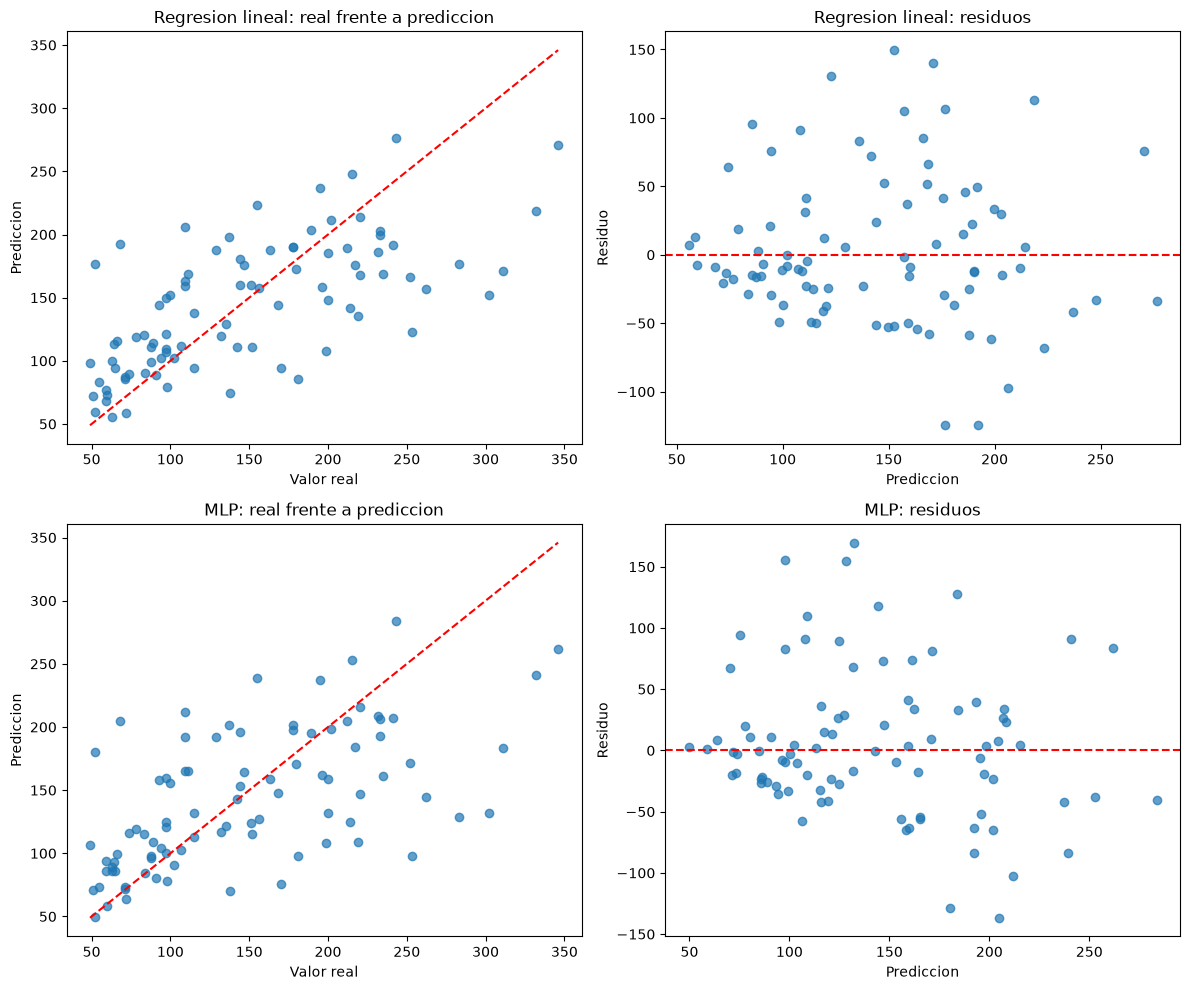

In [56]:
reales_test = np.asarray(y_reg_test)
residuos_lineal = reales_test - pred_lineal_test
residuos_mlp = reales_test - pred_mlp_reg_test

minimo_lineal = min(reales_test.min(), pred_lineal_test.min())
maximo_lineal = max(reales_test.max(), pred_lineal_test.max())
minimo_mlp = min(reales_test.min(), pred_mlp_reg_test.min())
maximo_mlp = max(reales_test.max(), pred_mlp_reg_test.max())

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(reales_test, pred_lineal_test, alpha=0.7)
axes[0, 0].plot([minimo_lineal, maximo_lineal], [minimo_lineal, maximo_lineal], "r--")
axes[0, 0].set_xlabel("Valor real")
axes[0, 0].set_ylabel("Prediccion")
axes[0, 0].set_title("Regresion lineal: real frente a prediccion")

axes[0, 1].scatter(pred_lineal_test, residuos_lineal, alpha=0.7)
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_xlabel("Prediccion")
axes[0, 1].set_ylabel("Residuo")
axes[0, 1].set_title("Regresion lineal: residuos")

axes[1, 0].scatter(reales_test, pred_mlp_reg_test, alpha=0.7)
axes[1, 0].plot([minimo_mlp, maximo_mlp], [minimo_mlp, maximo_mlp], "r--")
axes[1, 0].set_xlabel("Valor real")
axes[1, 0].set_ylabel("Prediccion")
axes[1, 0].set_title("MLP: real frente a prediccion")

axes[1, 1].scatter(pred_mlp_reg_test, residuos_mlp, alpha=0.7)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set_xlabel("Prediccion")
axes[1, 1].set_ylabel("Residuo")
axes[1, 1].set_title("MLP: residuos")

plt.tight_layout()
plt.show()

## 3.11 Dos ejemplos con errores absolutos grandes

In [57]:
errores_abs_lineal = np.abs(reales_test - pred_lineal_test)
posiciones_lineal = np.argsort(errores_abs_lineal)[-2:][::-1]

ejemplos_error_lineal = X_reg_test.iloc[posiciones_lineal].copy()
ejemplos_error_lineal["Valor real"] = reales_test[posiciones_lineal]
ejemplos_error_lineal["Prediccion"] = pred_lineal_test[posiciones_lineal]
ejemplos_error_lineal["Error absoluto"] = errores_abs_lineal[posiciones_lineal]

ejemplos_error_lineal

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Prediccion,Error absoluto
102,-0.092695,-0.044642,0.028284,-0.015999,0.036958,0.024991,0.056003,-0.039493,-0.005142,-0.001078,302.0,152.431667,149.568333
359,0.038076,0.050680,0.005650,0.032201,0.006687,0.017475,-0.024993,0.034309,0.014821,0.061054,311.0,171.054442,139.945558


In [58]:
errores_abs_mlp = np.abs(reales_test - pred_mlp_reg_test)
posiciones_mlp = np.argsort(errores_abs_mlp)[-2:][::-1]

ejemplos_error_mlp = X_reg_test.iloc[posiciones_mlp].copy()
ejemplos_error_mlp["Valor real"] = reales_test[posiciones_mlp]
ejemplos_error_mlp["Prediccion"] = pred_mlp_reg_test[posiciones_mlp]
ejemplos_error_mlp["Error absoluto"] = errores_abs_mlp[posiciones_mlp]

ejemplos_error_mlp

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Prediccion,Error absoluto
102,-0.092695,-0.044642,0.028284,-0.015999,0.036958,0.024991,0.056003,-0.039493,-0.005142,-0.001078,302.0,132.311086,169.688914
304,0.041708,0.050680,-0.038540,0.052858,0.076860,0.116430,-0.039719,0.071210,-0.022517,-0.013504,253.0,97.851940,155.148060


Los dos errores grandes de regresión fueron:

- Observacion 102: Su valor real era 302 y se predijo 152.432 con error absoluto de 149.568
- Observacion 359: Su valor real era 311 y se predijo 171.054 con error absoluto de 139.946

Los dos errores grandes del MLP fueron:

- Observacion 102: Su valor real era 302 y se predijo 132.311 con error absoluto de 169.689
- Observacion 304: Su valor real era de 253 y se predijo 97.852 con error absoluto de 155.148


No se puede concluir que las mediciones sean incorrectas ni que una característica aislada sea la causante de los errores. Las características están transformadas y estas filas, por sí solas, no permiten distinguir entre ruido, información predictiva faltante, casos atípicos o limitaciones del modelo.

## 3.12 Interpretación final

1. **¿Qué modelo tuvo el mejor desempeño?** 

La regresion lineal obtuvo el mejor resultado en estas metricas:
- MAE: 41.975.
- RMSE: 54.704.
- R²: 0.438.

Esto puede indicar que una relación lineal sea suficiente y optima para generalizar correctamente con esta cantidad de datos, sin embargo, las metricas no permiten identificar la causa con total certeza

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?** 

Esto sucede porque MAE calcula el promedio de los errores absolutos, es decir, representa el tamaño promedio del error sin penalizar de manera tan fuerte los casos extremos. Mientras que, RMSE eleva los errores al cuadrado antes de promediar y por eso penaliza mucho más los errores grandes.

3. **¿Cómo se interpreta un R² negativo?** 

Un R^2 negativo implica que el modelo predice peor que la media, esto no indica una correlación negativa.

4. **¿Qué efecto tuvo aumentar la regularización?** 

En Ridge y Lasso el aumentar la regularización se redujo la magnitud de los coeficientes y aumentó el error de entrenamiento ligeramente. Además de que, en Ridge, no aparecieron coeficientes nulos, mientras que en Lasso se convirtió un coeficiente a cero. En los dos modelos, el RMSE de validación disminuyo de forma ligera, lo que puede indicar una ligera reduccion del overfitting.

5. **¿Qué puede explicar los errores grandes?** 

Los errores grandes pueden deberse a observaciones poco representadas, objetivos atipicos o extremos, ruido, relaciones que no se pueden representar por estos modelos, entre otros. No se puede determinar una causa exacta examinando unicamente estas filas.

6. **¿Un coeficiente predictivo demuestra una relación causal?** 

No. Un coeficiente representa una asociación predictiva condicionada a las variables incluidas en el modelo. No demuestra causalidad porque pueden existir variables omitidas, confusión, o demás factores externos que no se incluyeron.